# Dataloader, (minis-)batches et perceptron

On s'intéresse au problème de classification de parcelles en Bretagne à partir d'images satellitaires de la zone prises en 2017.
L'objectif est de voir si, à partir de données partiellement étiquettées, on est capable de prédire la classe d'occupation du sol pour une nouvelle parcelle. On va commencer par installer le package ``breizhcrops`` ainsi que ``geopandas`` qui vont nous permettre de travailler. On importe également quelques librairies utiles : ``matplotlib`` pour le tracé de graphique notamment.

In [13]:
#!pip install --quiet breizhcrops geopandas

In [2]:
from breizhcrops import BreizhCrops
from breizhcrops.datasets.breizhcrops import BANDS as allbands
import matplotlib.pyplot as plt
import torch
import numpy as np

## Lecture et tranformation des données 

Les données peuvent être récupérées pour 5 régions : ``fr01`` (Côtes d'Armor), ``fr02`` (Finistère), ``fr03`` (Ille et Vilaine), ``fr04`` (Morbihan) et ``belle-ile``. Les données sont décrites plus précisement dans [cet article](https://arxiv.org/pdf/1905.11893.pdf) et il y a un site associé [https://breizhcrops.org/](https://breizhcrops.org/) où vous pouvez notamment visualiser les parcelles et leur classe associée.

Comme exemple, on va charger les données issues de Belle-île.

In [3]:
dataset = BreizhCrops(region="belle-ile", preload_ram=True)

classmapping.csv: 8.19kB [00:00, 23.4kB/s]
belle-ile.csv: 98.3kB [00:00, 195kB/s]                             


downloading breizhcrops_dataset/2017/L1C/belle-ile.h5.tar.gz


belle-ile.h5.tar.gz: 11.1MB [00:00, 18.2MB/s]                            


extracting breizhcrops_dataset/2017/L1C/belle-ile.h5.tar.gz to breizhcrops_dataset/2017/L1C/belle-ile.h5
removing breizhcrops_dataset/2017/L1C/belle-ile.h5.tar.gz
checking integrity by file size...
ok!


codes.csv: 24.6kB [00:00, 179kB/s]                             
loading data into RAM: 100%|██████████| 1049/1049 [00:00<00:00, 5902.05it/s]


Les données sont stockées dans ``dataset``. On peut afficher le nombre d'observations, le numéro des classes et le nombre total de classes, le nom des classes associées et le mapping.
On peut également visualiser la première observation.

In [4]:
print("nombre d'obervations: ", len(dataset))
print("il y a ", dataset.nclasses, " classes : ", dataset.classes)
print("qui correspondent aux cultures suivantes : ", dataset.klassenname)
print("**** la première observation : ")
x, y, field_id = dataset[0]
print("est de taille ", x.shape)
print("sa classe, ", y)
print("et l'index de la parcelle (non utilisé ici)", field_id)

nombre d'obervations:  1049
il y a  9  classes :  [0 1 2 3 4 5 6 7 8]
qui correspondent aux cultures suivantes :  <StringArray>
[           'barley',             'wheat',          'rapeseed',
              'corn',         'sunflower',          'orchards',
              'nuts', 'permanent meadows', 'temporary meadows']
Length: 9, dtype: str
**** la première observation : 
est de taille  torch.Size([45, 13])
sa classe,  tensor(7)
et l'index de la parcelle (non utilisé ici) 6059869


On voit donc que nos données ne sont pas "unidimensionelles" mais sont décrites ici par 13 variables et ont une longueur de 45 (c'est-à-dire que les données ont été observées sur 45 pas de temps).
On peut les visualiser notamment pour la première série temporelle.

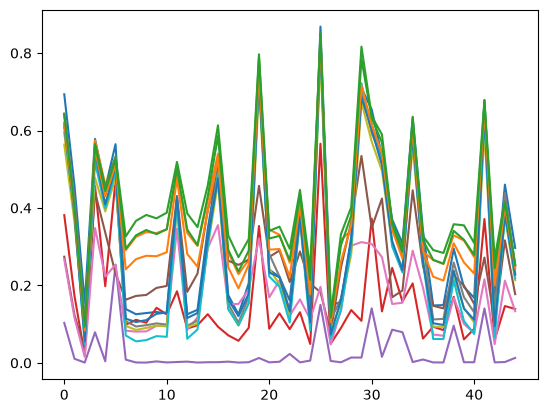

In [5]:
plt.plot(x)
plt.show()

On va commencer par travailler sur des séries univariées (càd représentées par une seule valeur). On va calculer le NDVI, qui est un indice de végétation (qui mesure globalement à quel point un pixel est "vert" -- en gros, cela correspond à une quantité de chlorophylle) et qui fonctionne assez bien lorsqu'il s'agit de représenter et classifier des données de végétation. Cet indice se calcule ici à partir des bandes d'indices 10 (proche infrarouge, NIR) et 6 (rouge) du tenseur — indexation à partir de 0 : NDVI = (NIR − Rouge) / (NIR + Rouge). 

Dans un premier temps, on récupère les données, que l'on stocke dans un tenseur ``X``, et leur classe d'occupation du sol, que l'on stocke dans ``y``. 

In [ ]:
X = torch.stack([dataset[i][0] for i in range(len(dataset))]) #on récupère les X de chaque observation que l'on concatène dans un tenseur
y = torch.tensor(np.array([dataset[i][1] for i in range(len(dataset))])) #idem pour les Y de chaque observation 
print(X.shape) #1049 observations, 45 moments, 13 canaux
ndvi = (X[:,:,10] - X[:,:,6]) / (X[:,:,10] + X[:,:,6] + 1e-8) #formule du NDVI (+ une petite constante pour éviter la division par 0)

torch.Size([1049, 45, 13])


<div class="admonition note">
<p class="admonition-title"></p>
Tracer la série à l'indice 166 (classe maïs) et la série 249 (classe blé). 
</div>

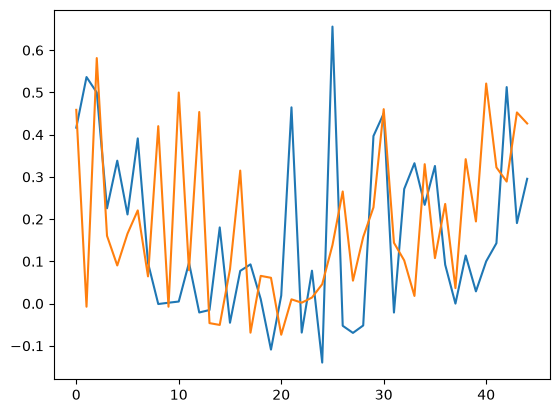

In [15]:
plt.plot(ndvi[166, :])
plt.plot(ndvi[249, :])
plt.show()

On voit que l'évolution du NDVI au cours du temps peut être différente en fonction des classes. On voit également que les données sont très bruitées, ce qui est probablement dû à des problèmes de couverture nuageuse en fonction des dates de collecte.

On espère être capable de classifier les séries en fonction de leur profil d'évolution du NDVI sur une année.

## Chargement des données dans un dataloader

On va utiliser la librairie ``pytorch`` pour effectuer notre tâche de classification sur notre jeu de données. La première étape est de créer une instance d’un ``dataloader`` qui va nous permettre de pouvoir itérer sur les données (et donc de pouvoir définir des minis-batches !).

On commence par créer une classe ``TSDataset`` qui permet de charger les données. Cette classe prend comme paramètre les observations (les ``data``) et les labels (les ``lab``). Elle *hérite* de la classe ``Dataset`` de pytorch.
Cette classe **doit** implémenter 3 fonctions : ``__init__``, ``__len__``, and ``__getitem__``.

On commence par importer la classe ``Dataset`` de pytorch.

### Fonction ``__init__``
On définit ici les différentes données avec lequelles on va travailler. Dans notre cas, nous avons les séries temporelles (que l'on va noter ``ts``) et les labels (notés ``labels``). On va donc plus tard instancier cette fonction avec nos données ``X`` et ``y``.

### Fonction ``__len__``
Cette fonction doit renvoyer le nombre d'observations, c'est-à-dire le nombre de lignes de ``ts`` ou de ``labels``.

### Fonction ``__getitem__``
Cette fonction doit renvoyer une observation à une position donnée en paramètre.

### Implémentation
On obtient donc :

In [7]:
from torch.utils.data import Dataset

class TSDataset(Dataset):
    def __init__(self, data, lab):
        self.ts = data
        self.labels = lab

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.ts[idx], self.labels[idx]

Cette classe nous permet de créer une instance d'un ``Dataset`` à partir de données en paramètre. Par exemple, si on veut charger l'ensemble de nos données, on va donc appeler :

In [16]:
X_all = TSDataset(ndvi, y)

<div class="admonition note">
<p class="admonition-title"></p>
Affichez la taille des **données** stockées dans ``X_all`` (vous devez trouver un Tensor de dimension 2) et affichez les 20 premières étiquettes de ``X_all``.
</div>

In [ ]:
print(f"Taille des données contenues dans X_all : {X_all.ts.size()}")
print(f"Les 20 premiers labels sont : {X_all.labels[:20]}")

Taille des données contenues dans X_all :torch.Size([1049, 45])
Les 20 premiers labels sont :tensor([7, 7, 7, 7, 5, 7, 7, 8, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7])


La classe ``DataLoader`` de pytorch est très utile ! Elle permet de pouvoir itérer sur un jeu de données. Elle prend comme paramètre une instance de ``Dataset`` (ce qui est le cas pour ``TSDataset``), une taille de batch et également un booléen ``shuffle`` qui indique si on veut « mélanger » les données.
On commence par importer la classe

In [ ]:
from torch.utils.data import DataLoader

batch_size = len(X_all)
dataloader_all = DataLoader(X_all, batch_size=batch_size, shuffle=True) 

for X, y in dataloader_all:
    print(f"Shape of X [batch size, length]: {X.shape}")
    print(len(y))
    break

Shape of X [batch size, length]: torch.Size([1049, 45])
1049


<div class="admonition note">
<p class="admonition-title"></p>
Expliquez le résultat de la cellule précédente.
</div>

<div class="admonition note">
<p class="admonition-title"></p>
Relancer le code précédent, cette fois ci en indiquant une taille de batch de 128.
</div>

On a créé un objet de classe Dataloader à partr de X_all, Dataloader contient un seul batch de 2 éléments (car le batch fait la taille du jeu de donnée entier), les données qu'on appelle X, et les labels qu'on appelle y.

In [27]:
batch_size = 128
dataloader_all = DataLoader(X_all, batch_size=batch_size, shuffle=True) 

for X, y in dataloader_all:
    print(f"Shape of X [batch size, length]: {X.shape}")
    print(len(y))
    break

Shape of X [batch size, length]: torch.Size([128, 45])
128


le batch a maintenant une taille de 128 observations, il n'y a toujours qu'un passage dans la boucle à cause de l'instruction break

<div class="admonition note">
<p class="admonition-title"></p>
Que se passe t-il si vous supprimez l'instruction ``break`` ? Quelle est la taille de batch du dernier batch ?
</div>

In [28]:
for X, y in dataloader_all:
    print(f"Shape of X [batch size, length]: {X.shape}")
    print(len(y))

Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([128, 45])
128
Shape of X [batch size, length]: torch.Size([25, 45])
25


le dernier batch ne fait que 25 observations car 1049 n'est pas divisible par 128, le reste de la division euclidienne est 25.

L'instruction ``shuffle = True`` permet de mélanger l'ordre des individus. Dans le code précédent, en ajoutant l'instruction ``break``, affichez les labels des 10 premiers individus du premier batch. Relancez et observer le résultat. Refaites ensuite la manipulation en supprimant l'étape de shuffle.

In [105]:
dataloader_all = DataLoader(X_all, batch_size=batch_size, shuffle=True) 

for X, y in dataloader_all:
    print(f"Shape of X [batch size, length]: {X.shape}")
    print(y[:10])
    break

dataloader_all = DataLoader(X_all, batch_size=batch_size, shuffle=False) 

for X, y in dataloader_all:
    print(f"Shape of X [batch size, length]: {X.shape}")
    print(y[:10])
    break

Shape of X [batch size, length]: torch.Size([128, 45])
tensor([3, 8, 7, 7, 8, 8, 7, 7, 7, 8])
Shape of X [batch size, length]: torch.Size([128, 45])
tensor([7, 7, 7, 7, 5, 7, 7, 8, 7, 7])


## Création des échantillons d'apprentissage, de validation (et de test)
Pour l'instant, nous n'avons travaillé que sur le fichier complet alors qu'il faut (évidemment !) considérer 3 échantillons (apprentissage pour apprendre le modèle, validation pour comparer plusieurs modèles entre eux et choisir les meilleurs paramètres, test pour évaluer les performances en généralisation). On va donc découper notre fichier initial en 2 : un échantillon d'apprentissage et un échantillon de validation. Un vrai échantillon de **test** serait sur une **autre zone** que Belle-Île (cf. l'exercice optionnel en fin de TD).

In [107]:
# On découpe en effectifs (nombres entiers) plutôt qu'en proportions [0.7, 0.3] :
# le passage de fractions à random_split dépend de la version de torch (comportement
# non garanti sur les versions plus anciennes). Les effectifs, eux, marchent partout.
n_total = len(X_all)
n_train = int(0.7 * n_total)
n_valid = n_total - n_train
g = torch.Generator().manual_seed(2024)   # découpage reproductible
train_dataset, valid_dataset = torch.utils.data.random_split(X_all, [n_train, n_valid], generator=g)

Ici, on a séparé le jeu de données en 2 : une première partie qui contient 70% des données et une deuxième qui en contient 30%.

<div class="admonition note">
<p class="admonition-title"></p>
Créez 2 dataloaders distincts : un premier pour les données d'apprentissage et un deuxième sur l'échantillon de validation. On choisira une taille de batch de 64.
</div>

In [112]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True) 
valid_dataloader = DataLoader(valid_dataset, batch_size=64, shuffle=True) 

## Apprendre un perceptron sur les séries temporelles unidimensionnelles
On va commencer par voir les séries temporelles comme des données tabulaires (c’est à dire que chaque temps
sera vu comme la réalisation d’une variable). On va chercher à apprendre un perceptron (une couche linéaire = régression logistique multinomiale) avec pytorch pour prédire la classe d'occupation des sols sur nos données.

### Création du modèle
On va d'abord créer un modèle nommé ``perceptron_ndvi`` qui permet d’instancier une seule couche linéaire (= régression logistique multinomiale). On ajoutera des couches cachées — le vrai MLP — au TD7.


<div class="admonition note">
<p class="admonition-title"></p>
Quelle doit être la taille de la couche d'entrée et la taille de la couche de sortie, notés ``input_size`` et ``output_size``dans le code suivant, lorsque l'on va instancier notre modèle ?
</div>

In [113]:
import torch.nn as nn

class perceptron_ndvi(nn.Module):
  def __init__(self, input_size, output_size):
    super(perceptron_ndvi, self).__init__()
    self.fc = nn.Linear(input_size, output_size)

  def forward(self, x):
    out = self.fc(x)
    return out

la couche d'entrée doit etre de taille 45 puisqu'on a 45 variables par observations, et la couche de sortie doit etre de taille 9 car il y a 9 classes 

On voit ici que l'on a la même syntaxe que l'on a vu au TD précédent : la classe *hérite* d'un module de pytorch et instancie 2 fonctions : ``__init__``, qui définit notre modèle (nos paramètres en fait) qui est ici une couche linéaire avec ``input_size`` neurones en entrée et ``output_size`` neurones en sortie. La fonction ``forward`` définit la fonction $f(x,w)$, qui est notre modèle.

On instancie ensuite notre modèle. 

<div class="admonition note">
<p class="admonition-title"></p>
Complétez l'instruction suivante. Quel est le nombre de paramètres de notre "réseau" ici ?
</div>

In [114]:
if 'model' in locals():
    del model
#del model #if it already exists
taille_entree = 45
taille_sortie = 9
model = perceptron_ndvi(input_size = taille_entree, output_size = taille_sortie)
print(model)

perceptron_ndvi(
  (fc): Linear(in_features=45, out_features=9, bias=True)
)


### Apprentissage du modèle

On va maintenant définir l’étape d’apprentissage dans une fonction ``train_loop`` qui prend en paramètres:

- un ``dataloader`` (les données d’apprentissage ici)
- un ``model`` (que l’on a défini dans la classe ``perceptron_ndvi``)
- une ``loss_fn`` (qui sera une soft max ici)
- un ``optimizer`` (un gradient stochastique puisque l'on a plusieurs batchs) !

On ajoute également un paramètre ``log`` qui permet d’afficher (par défaut) les différentes itérations de la boucle d’apprentissage. La fonction renvoie une liste qui contient la valeur de la loss une fois que tous les batchs ont été traités.

In [115]:
def train_loop(dataloader, model, loss_fn, optimizer, log=True):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        pred = model(X) #forward pass
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        if log and batch%5==0:
            loss_, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss_:>7f}  [{current:>5d}/{size:>5d}]")
    return loss.item()

On va utiliser la loss ``CrossEntropyLoss``, **sans** ajouter de ``softmax`` dans le modèle. En étudiant la doc PyTorch de ce module, expliquez pourquoi (indice : que fait ``CrossEntropyLoss`` en interne ?). 

https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html



In [116]:
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-1)   # lr pour la démo rapide (1 epoch)
train_loop(train_dataloader, model, loss, optimizer)

loss: 2.111712  [   64/  734]
loss: 1.829711  [  384/  734]
loss: 1.679866  [  704/  734]


1.5409889221191406

On a ainsi fait évoluer nos paramètres sur **une** seule epoch (c'est à dire que l'on a vu l'ensemble du jeu de données une seule fois).

<div class="admonition note">
<p class="admonition-title"></p>
Modifiez le code précédent afin que l'on puisse visualiser l'évolution de la loss au long de 100 epochs et non plus une seule.
</div>

loss: 1.605798  [   64/  734]
loss: 1.454521  [  384/  734]
loss: 1.319645  [  704/  734]
loss: 1.240646  [   64/  734]
loss: 1.296124  [  384/  734]
loss: 1.311939  [  704/  734]
loss: 1.183719  [   64/  734]
loss: 1.285079  [  384/  734]
loss: 1.175054  [  704/  734]
loss: 1.210588  [   64/  734]
loss: 1.156075  [  384/  734]
loss: 1.271296  [  704/  734]
loss: 1.065149  [   64/  734]
loss: 1.065613  [  384/  734]
loss: 1.123204  [  704/  734]
loss: 1.065230  [   64/  734]
loss: 1.433280  [  384/  734]
loss: 1.137813  [  704/  734]
loss: 1.204652  [   64/  734]
loss: 1.292444  [  384/  734]
loss: 1.196152  [  704/  734]
loss: 1.154016  [   64/  734]
loss: 1.081247  [  384/  734]
loss: 1.235309  [  704/  734]
loss: 1.220396  [   64/  734]
loss: 1.337332  [  384/  734]
loss: 1.088274  [  704/  734]
loss: 1.141985  [   64/  734]
loss: 1.173078  [  384/  734]
loss: 1.126396  [  704/  734]
loss: 1.051420  [   64/  734]
loss: 1.117824  [  384/  734]
loss: 1.077965  [  704/  734]
loss: 1.17

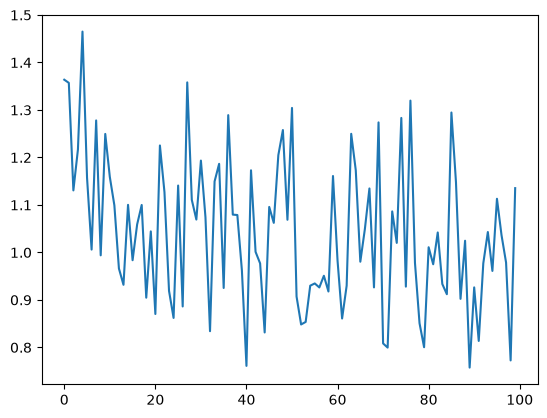

In [117]:
loss_list = []
for _ in range(100):
    loss_list.append(train_loop(train_dataloader, model, loss, optimizer))
plt.plot(loss_list)

non, la loss varie énormément, elle a l'air de baisser par rapport au temps 0, mais ce n'est pas flagrant

Au vu de l'évolution de la loss, êtes vous satisfaits de l'apprentissage de votre modèle ? Que peut-on changer pour que ça aille mieux ?

**Attention** : pour **repartir d'un entraînement neuf**, il faut **réinitialiser les poids** (sinon on continue d'entraîner le modèle déjà appris). On recrée donc le modèle avant chaque nouvel entraînement : 

```python 
if 'model' in locals():
    del model
```

(le ``if`` teste si le modèle existe déjà). Les *gradients*, eux, sont déjà remis à zéro à chaque batch par ``optimizer.zero_grad()`` dans la ``train_loop``.

In [ ]:
if 'model' in locals():
    del model

def train_loop(dataloader, model, loss_fn, optimizer, log=True):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        pred = model(X) #forward pass
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        if log and batch%5==0:
            loss_, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss_:>7f}  [{current:>5d}/{size:>5d}]")
    return loss.item()

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-1)

loss_list = []
for _ in range(100):
    loss_list.append(train_loop(train_dataloader, model, loss, optimizer))
plt.plot(loss_list)

On va maintenant calculer l'accuracy finale. 

<div class="admonition note">
<p class="admonition-title"></p>
Etudiez le code suivant et essayer de comprendre ce qu'il produit
</div>

In [70]:
# on récupère les séries/labels du SOUS-ENSEMBLE d'apprentissage (pas tout le dataset !)
ts_train = train_dataset.dataset.ts[train_dataset.indices]
lab_train = train_dataset.dataset.labels[train_dataset.indices]
y_pred = model(ts_train)
proba = torch.softmax(y_pred, dim=1)
y_hat = torch.argmax(proba, dim=1)
accuracy = (y_hat == lab_train).float().mean()
print(accuracy)

tensor(0.5748)


<div class="admonition note">
<p class="admonition-title"></p>
Pourquoi n'est-il pas nécessaire d'utiliser la loss de ``cross entropy`` ici ?
</div>

## Evaluation du modèle
On définit maintenant une étape de ``validation`` pour évaluer les performances du modèle. On vérifie bien que l'on ne modifie pas nos gradients lorsque l'on effectue cette étape !

In [71]:
def test_loop(dataloader, model, loss_fn, log=True):
    model.eval() #evaluating the model
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    if log:
        print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, loss: {test_loss:>8f} \n")
    return test_loss, 100*correct

In [ ]:
epochs = 1000
loss_test = []
loss_train = []
acc_test = []
if 'model' in locals():
    del model
if 'loss' in locals():
    del loss
if 'optimizer' in locals():
    del optimizer

model = perceptron_ndvi(input_size = train_dataset.dataset.ts.shape[1], output_size = dataset.nclasses)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-4)   # lr plus petit (entraînement long) ; hyperparamètre à ajuster (cf. CM4)

for t in range(epochs):
    loss_train.append(train_loop(train_dataloader, model, loss_fn, optimizer))
    l, a = test_loop(valid_dataloader, model, loss_fn)
    loss_test.append(l)
    acc_test.append(a)
print("Done!")


<div class="admonition note">
<p class="admonition-title"></p>
Que peut-on dire ici ? Est ce que le modèle a convergé à votre avis ? Est ce un ``bon`` modèle ? Tracez l'évolution de la loss et de l'accuracy au cours des epochs.
</div>


<div class="admonition note">
<p class="admonition-title"></p>
Il y a quelque chose de bizarre... J'ai noté les résultats ``acc_test`` et ``loss_test``. Pourquoi n'est ce pas utile d'avoir un jeu de validation ici ?
</div>


<div class="admonition note">
<p class="admonition-title"></p>
Finalement, cette fonction ``softmax`` est une extension de la fonction sigmoïde pour plus de 2 classes. A quoi correspond le perceptron avec avec une seule couche dans ce cas ?
</div>

<div class="admonition tip">
<p class="admonition-title"></p>

**Pour aller plus loin — généralisation inter-région.** Le vrai test de généralisation se fait sur une **autre région**. Chargez-en une (p. ex. `BreizhCrops(region="fr04")`, Morbihan — #emoji.warning téléchargement plus long), calculez le NDVI de la même façon, créez un `DataLoader`, et évaluez votre modèle dessus avec `test_loop`. L'accuracy baisse-t-elle par rapport à la validation (Belle-Île) ? C'est le phénomène de *drift* de distribution.

</div>